# Proyek Analisis Data: Bike sharing dataset
- **Nama:** Jovan Bagas Pangestu
- **Email:** jovanbagas37@gmail.com
- **ID Dicoding:** jovan_bagas_pangestu

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan sepeda per jam tertinggi dan terendah pada hari kerja dibandingkan akhir pekan/libur selama 2011–2012, dan berapa persen penyewaan hari kerja yang terjadi pada jam sibuk (07.00–09.59 dan 16.00–19.59), sebagai dasar penentuan jam penyediaan sepeda dan jadwal perawatan armada?
- **Pertanyaan 2:** Berapa rata-rata penyewaan sepeda per hari pada tiap musim dan tiap kondisi cuaca selama 2011–2012, serta musim dan cuaca apa yang memiliki rata-rata terendah, sebagai dasar penentuan jadwal promosi dan perawatan armada besar?
- **Pertanyaan 3:** Berapa persen pertumbuhan total penyewaan tahun 2012 dibandingkan 2011, bulan apa yang tertinggi dan terendah, dan berapa porsi serta pertumbuhan pengguna registered dibanding casual, sebagai dasar perencanaan kapasitas armada dan strategi promosi keanggotaan?

## Import Semua Packages/Library yang Digunakan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Data Wrangling

### Gathering Data

#### Load day.csv dan hour.csv

In [3]:
day_raw = pd.read_csv("/content/day.csv")
hour_raw = pd.read_csv("/content/hour.csv")

print("Ukuran day.csv :", day_raw.shape)
print("Ukuran hour.csv:", hour_raw.shape)
day_raw.head()

Ukuran day.csv : (731, 16)
Ukuran hour.csv: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
hour_raw.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**

- day.csv berisi 731 baris (1 baris = 1 hari) dan hour.csv berisi 17.379 baris (1 baris = 1 jam). Kolom hr hanya ada di hour.csv.
- Kolom season, weathersit, weekday, dan yr masih berupa kode angka, sedangkan temp, atemp, hum, dan windspeed berupa angka 0–1 (sudah dinormalisasi). Keduanya perlu diubah supaya mudah dibaca.

### Assessing Data

#### Cek tipe data, missing value, dan data duplikat

In [5]:
day_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [6]:
print("Missing value day :", day_raw.isnull().sum().sum())
print("Missing value hour:", hour_raw.isnull().sum().sum())
print("Duplikat day :", day_raw.duplicated().sum())
print("Duplikat hour:", hour_raw.duplicated().sum())

Missing value day : 0
Missing value hour: 0
Duplikat day : 0
Duplikat hour: 0


#### Masalah 1: tipe data `dteday` masih berupa teks (object), bukan tanggal

In [7]:
print(day_raw["dteday"].dtype)
print(hour_raw["dteday"].dtype)

object
object


#### Masalah 2: label `season` di Readme tidak sesuai data

In [8]:
# Readme= 1:springer, 2:summer, 3:fall, 4:winter. Kita cek dengan melihat bulannya.
print(pd.crosstab(day_raw["mnth"], day_raw["season"]))
print()
print("Rata-rata penyewaan harian per kode season:")
print(day_raw.groupby("season")["cnt"].mean().round(0))

season   1   2   3   4
mnth                  
1       62   0   0   0
2       57   0   0   0
3       40  22   0   0
4        0  60   0   0
5        0  62   0   0
6        0  40  20   0
7        0   0  62   0
8        0   0  62   0
9        0   0  44  16
10       0   0   0  62
11       0   0   0  60
12      22   0   0  40

Rata-rata penyewaan harian per kode season:
season
1    2604.0
2    4992.0
3    5644.0
4    4728.0
Name: cnt, dtype: float64


In [9]:
# Cek kode weekday dengan membandingkan ke nama hari dari tanggal
nama_hari = pd.to_datetime(day_raw["dteday"]).dt.day_name()
print(pd.crosstab(day_raw["weekday"], nama_hari))

dteday   Friday  Monday  Saturday  Sunday  Thursday  Tuesday  Wednesday
weekday                                                                
0             0       0         0     105         0        0          0
1             0     105         0       0         0        0          0
2             0       0         0       0         0      104          0
3             0       0         0       0         0        0        104
4             0       0         0       0       104        0          0
5           104       0         0       0         0        0          0
6             0       0       105       0         0        0          0


#### Masalah 3: kelembapan (`hum`) bernilai 0

In [10]:
print("Jumlah hum = 0 di day :", (day_raw["hum"] == 0).sum())
print(day_raw[day_raw["hum"] == 0][["dteday", "hum", "cnt"]])
print("Jumlah hum = 0 di hour:", (hour_raw["hum"] == 0).sum())
print("Tanggalnya:", hour_raw[hour_raw["hum"] == 0]["dteday"].unique().tolist())

Jumlah hum = 0 di day : 1
        dteday  hum  cnt
68  2011-03-10  0.0  623
Jumlah hum = 0 di hour: 22
Tanggalnya: ['2011-03-10']


#### Masalah 4: kecepatan angin (`windspeed`) bernilai 0 di data jam

In [11]:
jumlah_nol = (hour_raw["windspeed"] == 0).sum()
print("windspeed = 0 di hour:", jumlah_nol, "baris =", round(jumlah_nol / len(hour_raw) * 100, 1), "%")
print("windspeed paling kecil di day:", round(day_raw["windspeed"].min(), 4))

windspeed = 0 di hour: 2180 baris = 12.5 %
windspeed paling kecil di day: 0.0224


#### Masalah 5: ada jam yang tidak tercatat di data jam

In [12]:
jam_seharusnya = 731 * 24
print("Jam seharusnya:", jam_seharusnya)
print("Jam tercatat  :", len(hour_raw))
print("Jam hilang    :", jam_seharusnya - len(hour_raw))
print()
# tiap jam seharusnya muncul 731 kali
print(hour_raw["hr"].value_counts().sort_index().loc[[2, 3, 4, 5, 12]])

Jam seharusnya: 17544
Jam tercatat  : 17379
Jam hilang    : 165

hr
2     715
3     697
4     697
5     717
12    728
Name: count, dtype: int64


#### Masalah 6: outlier pada pengguna casual dan hari dengan penyewaan sangat rendah

Batas atas outlier casual: 2266.75
Jumlah hari outlier casual: 44


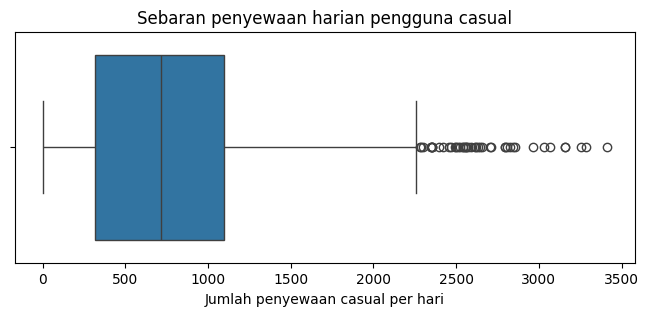

         dteday  cnt  weathersit
667  2012-10-29   22           3
26   2011-01-27  431           1
725  2012-12-26  441           3


In [13]:
q1 = day_raw["casual"].quantile(0.25)
q3 = day_raw["casual"].quantile(0.75)
iqr = q3 - q1
batas_atas = q3 + 1.5 * iqr
print("Batas atas outlier casual:", batas_atas)
print("Jumlah hari outlier casual:", (day_raw["casual"] > batas_atas).sum())

plt.figure(figsize=(8, 3))
sns.boxplot(x=day_raw["casual"])
plt.title("Sebaran penyewaan harian pengguna casual")
plt.xlabel("Jumlah penyewaan casual per hari")
plt.show()

print(day_raw.sort_values("cnt").head(3)[["dteday", "cnt", "weathersit"]])

In [14]:
outlier = day_raw[day_raw["casual"] > batas_atas]
nama_musim = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
print("Outlier menurut workingday (0 = akhir pekan/libur):")
print(outlier["workingday"].value_counts())
print("\nOutlier menurut musim:")
print(outlier["season"].map(nama_musim).value_counts())

Outlier menurut workingday (0 = akhir pekan/libur):
workingday
0    43
1     1
Name: count, dtype: int64

Outlier menurut musim:
season
Spring    20
Summer    16
Fall       7
Winter     1
Name: count, dtype: int64


#### Cek konsistensi data

In [15]:
print("cnt != casual + registered (day) :", (day_raw["cnt"] != day_raw["casual"] + day_raw["registered"]).sum())
print("cnt != casual + registered (hour):", (hour_raw["cnt"] != hour_raw["casual"] + hour_raw["registered"]).sum())
print("Total cnt day :", day_raw["cnt"].sum())
print("Total cnt hour:", hour_raw["cnt"].sum())
print("Jumlah data weathersit = 4 (hour):", (hour_raw["weathersit"] == 4).sum())
print("Jumlah data weathersit = 4 (day) :", (day_raw["weathersit"] == 4).sum())

cnt != casual + registered (day) : 0
cnt != casual + registered (hour): 0
Total cnt day : 3292679
Total cnt hour: 3292679
Jumlah data weathersit = 4 (hour): 3
Jumlah data weathersit = 4 (day) : 0


**Steps to Take (rencana cleaning):**
1. **Tipe data:** ubah `dteday` menjadi tipe tanggal (`datetime`).
2. **Label season salah:** kode 1 jatuh pada bulan Desember–Maret, jadi 1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall. Label dibuat mengikuti data, bukan Readme.
3. **Kolom berkode dan ternormalisasi:** ubah kode `yr`, `weekday`, `weathersit`, `workingday` menjadi label, lalu kembalikan `temp` (x41), `atemp` (x50), `hum` (x100), `windspeed` (x67) ke skala asli sesuai Readme.
4. **hum = 0:** hanya terjadi pada 2011-03-10, jadi nilainya diganti kosong (NaN) lalu diisi dengan interpolasi dari hari/jam di sekitarnya.
5. **windspeed = 0 (data jam):** dianggap tidak terukur, diganti NaN, dan tidak dipakai untuk analisis per jam.
6. **Jam tidak tercatat (165 jam):** tidak diisi karena tidak ada informasi pasti; cukup dicatat sebagai keterbatasan.
7. **Outlier:** dibiarkan karena merupakan data pengamatan nyata, bukan kesalahan input. Dari 44 hari outlier casual, 43 hari adalah akhir pekan/libur dan 36 hari jatuh pada Spring atau Summer (hasil cell di atas). Hari dengan `cnt` terendah (2012-10-29, cnt = 22) bercuaca Light Rain/Snow (`weathersit` 3).
8. **weathersit = 4:** hanya 3 jam dan tidak ada di data harian, jadi tidak dianalisis.
9. Kolom `instant` dihapus karena hanya nomor urut.

**Insight:**
- Tidak ada missing value maupun data duplikat, tetapi ada 6 masalah lain: tipe data tanggal, label musim yang salah di Readme, nilai hum 0, windspeed 0, jam tidak tercatat, dan outlier.
- Total `cnt` di `day.csv` sama dengan total di `hour.csv`, dan `cnt = casual + registered` selalu benar, jadi kedua file konsisten.
- Jika label musim dari Readme dipakai, kesimpulannya bisa terbalik (musim dingin terlihat seperti "springer").

### Cleaning Data

#### Memperbaiki tipe data dan memberi label

In [16]:
# 1. ubah teks menjadi tipe tanggal
day_df = day_raw.copy()
hour_df = hour_raw.copy()
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# 2. kamus label
label_season = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
label_weather = {1: "Clear", 2: "Mist/Cloudy", 3: "Light Rain/Snow", 4: "Heavy Rain/Snow"}
label_weekday = {0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday", 4: "Thursday", 5: "Friday", 6: "Saturday"}
label_day_type = {1: "Hari kerja", 0: "Akhir pekan / libur"}

# 3. ubah kode menjadi label (data harian)
day_df["season"] = day_df["season"].map(label_season)
day_df["weather"] = day_df["weathersit"].map(label_weather)
day_df["weekday"] = day_df["weekday"].map(label_weekday)
day_df["day_type"] = day_df["workingday"].map(label_day_type)
day_df["year"] = day_df["yr"].map({0: 2011, 1: 2012})
day_df["month"] = day_df["mnth"]

# ubah kode menjadi label (data jam)
hour_df["season"] = hour_df["season"].map(label_season)
hour_df["weather"] = hour_df["weathersit"].map(label_weather)
hour_df["weekday"] = hour_df["weekday"].map(label_weekday)
hour_df["day_type"] = hour_df["workingday"].map(label_day_type)
hour_df["year"] = hour_df["yr"].map({0: 2011, 1: 2012})
hour_df["month"] = hour_df["mnth"]

print(day_df["season"].value_counts())

season
Summer    188
Spring    184
Winter    181
Fall      178
Name: count, dtype: int64


#### Mengembalikan suhu, kelembapan, dan kecepatan angin ke skala asli

In [17]:
day_df["temp_c"] = (day_df["temp"] * 41).round(2)
day_df["hum_pct"] = day_df["hum"] * 100
day_df["windspeed_orig"] = day_df["windspeed"] * 67

hour_df["temp_c"] = (hour_df["temp"] * 41).round(2)
hour_df["hum_pct"] = hour_df["hum"] * 100
hour_df["windspeed_orig"] = hour_df["windspeed"] * 67

day_df[["temp_c", "hum_pct", "windspeed_orig"]].describe().round(2)

,temp_c,hum_pct,windspeed_orig
count,731.00,731.00,731.00
mean,20.31,62.79,12.76
std,7.51,14.24,5.19
min,2.42,0.00,1.50
25%,13.82,52.00,9.04
50%,20.43,62.67,12.13
75%,26.88,73.02,15.63
max,35.33,97.25,34.00


#### Memperbaiki hum = 0 dan windspeed = 0

In [18]:
# hum = 0 -> kosong -> diisi interpolasi
day_df["hum_pct"] = day_df["hum_pct"].replace(0, np.nan).interpolate()
hour_df["hum_pct"] = hour_df["hum_pct"].replace(0, np.nan).interpolate()
print("Sisa hum = 0:", (day_df["hum_pct"] == 0).sum(), (hour_df["hum_pct"] == 0).sum())
print("hum_pct 2011-03-10 (harian):", day_df[day_df["dteday"] == "2011-03-10"]["hum_pct"].round(1).values)

# windspeed = 0 di data jam -> dianggap tidak terukur
hour_df["windspeed_orig"] = hour_df["windspeed_orig"].replace(0, np.nan)
print("windspeed tidak terukur (hour):", hour_df["windspeed_orig"].isnull().sum())

Sisa hum = 0: 0 0
hum_pct 2011-03-10 (harian): [71.2]
windspeed tidak terukur (hour): 2180


#### Menghapus kolom yang tidak dipakai

In [19]:
kolom_hapus_day = ["instant", "yr", "mnth", "weathersit", "temp", "atemp", "hum", "windspeed"]
day_df = day_df.drop(columns=kolom_hapus_day)
hour_df = hour_df.drop(columns=kolom_hapus_day)
print(day_df.columns.tolist())

['dteday', 'season', 'holiday', 'weekday', 'workingday', 'casual', 'registered', 'cnt', 'weather', 'day_type', 'year', 'month', 'temp_c', 'hum_pct', 'windspeed_orig']


#### Membuat kelompok (binning / manual grouping)

In [20]:
# kelompok suhu (dalam derajat Celsius)
day_df["temp_group"] = pd.cut(day_df["temp_c"],
                              bins=[-100, 10, 20, 30, 100],
                              labels=["Dingin (<10 C)", "Sejuk (10-20 C)", "Hangat (20-30 C)", "Panas (>30 C)"])

# kelas permintaan harian: dibagi 3 sama banyak (rendah, sedang, tinggi)
day_df["demand_tier"] = pd.qcut(day_df["cnt"], 3, labels=["Rendah", "Sedang", "Tinggi"])

# kelompok waktu pada data jam
hour_df["time_of_day"] = pd.cut(hour_df["hr"],
                                bins=[-1, 5, 9, 15, 19, 23],
                                labels=["Dini hari (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"])

print(day_df["temp_group"].value_counts().sort_index())
print(day_df["demand_tier"].value_counts().sort_index())

temp_group
Dingin (<10 C)       60
Sejuk (10-20 C)     299
Hangat (20-30 C)    300
Panas (>30 C)        72
Name: count, dtype: int64
demand_tier
Rendah    244
Sedang    244
Tinggi    243
Name: count, dtype: int64


#### Menyimpan data bersih untuk dashboard

In [21]:
os.makedirs("dashboard", exist_ok=True)

main_df = pd.merge(
    left=hour_df,
    right=day_df[["dteday", "temp_c", "hum_pct", "windspeed_orig", "casual", "registered", "cnt"]],
    on="dteday",
    how="left",
    suffixes=("_hour", "_day")
)

main_df.to_csv("dashboard/main_data.csv", index=False)
print("Berhasil disimpan!")

Berhasil disimpan!


**Insight:**
- Label musim kini sesuai bulan (Winter = Desember–Februari), kode cuaca dan hari sudah menjadi teks, dan suhu kembali ke derajat Celsius (`temp_c`).
- Nilai `hum_pct = 0` sudah diisi, dan `windspeed_orig = 0` di data jam dianggap tidak terukur sehingga tidak dipakai.
- Data bersih dari `hour_df` dan `day_df` telah digabungkan (*merged*) dan disimpan ke dalam satu file `dashboard/main_data.csv` untuk kebutuhan *dashboard*.

## Exploratory Data Analysis (EDA)

### Explore data secara umum

In [22]:
print("Periode:", day_df["dteday"].min().date(), "sampai", day_df["dteday"].max().date())
print("Total penyewaan:", day_df["cnt"].sum())
print("Rata-rata per hari:", round(day_df["cnt"].mean()))
print("Rata-rata per jam :", round(hour_df["cnt"].mean(), 1))
day_df[["temp_c", "hum_pct", "windspeed_orig", "casual", "registered", "cnt"]].describe().round(2)

Periode: 2011-01-01 sampai 2012-12-31
Total penyewaan: 3292679
Rata-rata per hari: 4504
Rata-rata per jam : 189.5


,temp_c,hum_pct,windspeed_orig,casual,registered,cnt
count,731.00,731.00,731.00,731.00,731.00,731.00
mean,20.31,62.89,12.76,848.18,3656.17,4504.35
std,7.51,14.06,5.19,686.62,1560.26,1937.21
min,2.42,18.79,1.50,2.00,20.00,22.00
25%,13.82,52.10,9.04,315.50,2497.00,3152.00
50%,20.43,62.75,12.13,713.00,3662.00,4548.00
75%,26.88,73.02,15.63,1096.00,4776.50,5956.00
max,35.33,97.25,34.00,3410.00,6946.00,8714.00


### Explore pola per jam (Pertanyaan 1)

In [23]:
hour_kerja = hour_df[hour_df["day_type"] == "Hari kerja"]
hour_libur = hour_df[hour_df["day_type"] == "Akhir pekan / libur"]

rata_kerja = hour_kerja.groupby("hr")["cnt"].mean()
rata_libur = hour_libur.groupby("hr")["cnt"].mean()

print("3 jam terendah hari kerja:")
print(rata_kerja.nsmallest(3).round(1))
print("3 jam terendah akhir pekan/libur:")
print(rata_libur.nsmallest(3).round(1))
print("\nRata-rata pukul 02.00-05.00 (per jam):")
print(pd.DataFrame({"Hari kerja": rata_kerja.loc[2:5], "Akhir pekan/libur": rata_libur.loc[2:5]}).round(1))

jam_sibuk = [7, 8, 9, 16, 17, 18, 19]
persen_sibuk = hour_kerja[hour_kerja["hr"].isin(jam_sibuk)]["cnt"].sum() / hour_kerja["cnt"].sum() * 100
print("\nPorsi penyewaan hari kerja pada jam sibuk:", round(persen_sibuk, 1), "%")
print("Rata-rata jam 03-04 (hari kerja):", round(hour_kerja[hour_kerja["hr"].isin([3, 4])]["cnt"].mean(), 1))

3 jam terendah hari kerja:
hr
3    4.9
4    5.4
2    8.7
Name: cnt, dtype: float64
3 jam terendah akhir pekan/libur:
hr
4     8.3
5     8.7
6    18.7
Name: cnt, dtype: float64

Rata-rata pukul 02.00-05.00 (per jam):
    Hari kerja  Akhir pekan/libur
hr                               
2          8.7               53.2
3          4.9               25.8
4          5.4                8.3
5         24.9                8.7

Porsi penyewaan hari kerja pada jam sibuk: 57.9 %
Rata-rata jam 03-04 (hari kerja): 5.2


### Explore musim dan cuaca (Pertanyaan 2)

In [24]:
urut_musim = ["Winter", "Spring", "Summer", "Fall"]
urut_cuaca = ["Clear", "Mist/Cloudy", "Light Rain/Snow"]

rata_musim = day_df.groupby("season")["cnt"].mean().loc[urut_musim]
rata_cuaca = day_df.groupby("weather")["cnt"].mean().loc[urut_cuaca]
hari_musim = day_df["season"].value_counts().loc[urut_musim]
hari_cuaca = day_df["weather"].value_counts().loc[urut_cuaca]

print(rata_musim.round(1))
print(rata_cuaca.round(1))
print("Jumlah hari per cuaca:", hari_cuaca.to_dict())

print("\nWinter dibanding Summer:", round((rata_musim["Winter"] / rata_musim["Summer"] - 1) * 100, 1), "%")
print("Mist/Cloudy dibanding Clear:", round((rata_cuaca["Mist/Cloudy"] / rata_cuaca["Clear"] - 1) * 100, 1), "%")
print("Light Rain/Snow dibanding Clear:", round((rata_cuaca["Light Rain/Snow"] / rata_cuaca["Clear"] - 1) * 100, 1), "%")
print("\nKorelasi suhu dengan cnt:", round(day_df["temp_c"].corr(day_df["cnt"]), 2))

season
Winter    2604.1
Spring    4992.3
Summer    5644.3
Fall      4728.2
Name: cnt, dtype: float64
weather
Clear              4876.8
Mist/Cloudy        4035.9
Light Rain/Snow    1803.3
Name: cnt, dtype: float64
Jumlah hari per cuaca: {'Clear': 463, 'Mist/Cloudy': 247, 'Light Rain/Snow': 21}

Winter dibanding Summer: -53.9 %
Mist/Cloudy dibanding Clear: -17.2 %
Light Rain/Snow dibanding Clear: -63.0 %

Korelasi suhu dengan cnt: 0.63


### Explore pertumbuhan dan jenis pengguna (Pertanyaan 3)

In [25]:
per_tahun = day_df.groupby("year")[["casual", "registered", "cnt"]].sum()
print(per_tahun)
pertumbuhan = (per_tahun.loc[2012] / per_tahun.loc[2011] - 1) * 100
print("\nPertumbuhan 2012 vs 2011 (%):")
print(pertumbuhan.round(1))
print("\nPorsi registered (%):")
print((per_tahun["registered"] / per_tahun["cnt"] * 100).round(1))

per_bulan = day_df.pivot_table(index="month", columns="year", values="cnt", aggfunc="sum")
per_bulan["naik_persen"] = ((per_bulan[2012] / per_bulan[2011] - 1) * 100).round(1)
print()
print(per_bulan)

print("\nBulan tertinggi 2012:", per_bulan[2012].idxmax(), "=", per_bulan[2012].max())
print("Bulan terendah 2011 :", per_bulan[2011].idxmin(), "=", per_bulan[2011].min())

casual_persen = day_df.groupby("day_type")["casual"].sum() / day_df.groupby("day_type")["cnt"].sum() * 100
print("\nPorsi casual (%):")
print(casual_persen.round(1))

      casual  registered      cnt
year                             
2011  247252      995851  1243103
2012  372765     1676811  2049576

Pertumbuhan 2012 vs 2011 (%):
casual        50.8
registered    68.4
cnt           64.9
dtype: float64

Porsi registered (%):
year
2011    80.1
2012    81.8
dtype: float64

year     2011    2012  naik_persen
month                             
1       38189   96744        153.3
2       48215  103137        113.9
3       64045  164875        157.4
4       94870  174224         83.6
5      135821  195865         44.2
6      143512  202830         41.3
7      141341  203607         44.1
8      136691  214503         56.9
9      127418  218573         71.5
10     123511  198841         61.0
11     102167  152664         49.4
12      87323  123713         41.7

Bulan tertinggi 2012: 9 = 218573
Bulan terendah 2011 : 1 = 38189

Porsi casual (%):
day_type
Akhir pekan / libur    31.7
Hari kerja             13.2
dtype: float64


**Insight:**
- Pola jam berbeda: hari kerja punya dua puncak (pukul 08.00 dan 17.00–18.00), sedangkan akhir pekan/libur punya satu puncak lebar di siang hari (sekitar pukul 13.00).
- Penyewaan turun saat cuaca memburuk, dan musim dingin jauh lebih rendah dari musim lain.
- Penyewaan 2012 lebih tinggi di semua bulan, dan pengguna *registered* mendominasi.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa rata-rata penyewaan sepeda per jam tertinggi dan terendah pada hari kerja dibandingkan akhir pekan/libur selama 2011–2012, dan berapa persen penyewaan hari kerja yang terjadi pada jam sibuk (07.00–09.59 dan 16.00–19.59), sebagai dasar penentuan jam penyediaan sepeda dan jadwal perawatan armada?

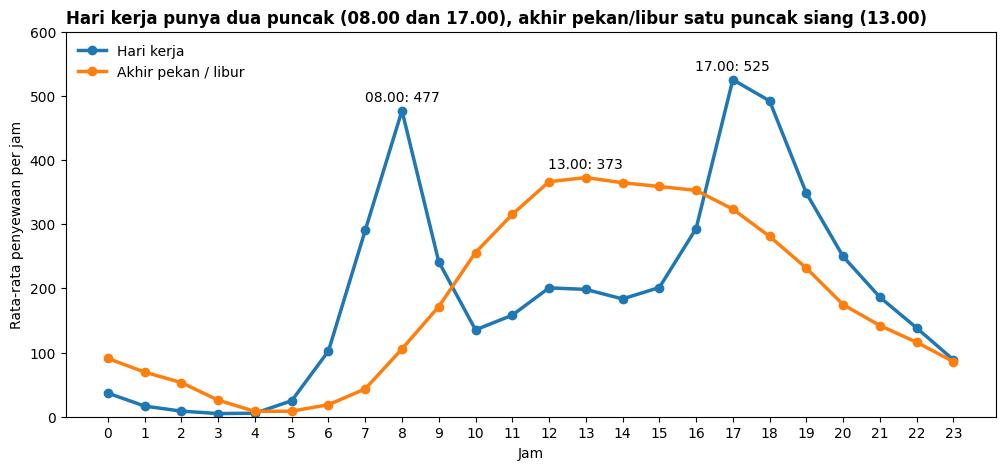

In [26]:
plt.figure(figsize=(12, 5))
plt.plot(rata_kerja.index, rata_kerja.values, linewidth=2.5, marker="o", label="Hari kerja")
plt.plot(rata_libur.index, rata_libur.values, linewidth=2.5, marker="o", label="Akhir pekan / libur")

# tulis angka pada jam puncak
plt.text(8, rata_kerja[8] + 15, "08.00: " + str(round(rata_kerja[8])), ha="center")
plt.text(17, rata_kerja[17] + 15, "17.00: " + str(round(rata_kerja[17])), ha="center")
plt.text(13, rata_libur[13] + 15, "13.00: " + str(round(rata_libur[13])), ha="center")

plt.title("Hari kerja punya dua puncak (08.00 dan 17.00), akhir pekan/libur satu puncak siang (13.00)", loc="left", fontweight="bold")
plt.xlabel("Jam")
plt.ylabel("Rata-rata penyewaan per jam")
plt.xticks(range(24))
plt.ylim(0, 600)
plt.legend(loc="upper left", frameon=False)
plt.show()

### Pertanyaan 2: Berapa rata-rata penyewaan sepeda per hari pada tiap musim dan tiap kondisi cuaca selama 2011–2012, serta musim dan cuaca apa yang memiliki rata-rata terendah, sebagai dasar penentuan jadwal promosi dan perawatan armada besar?

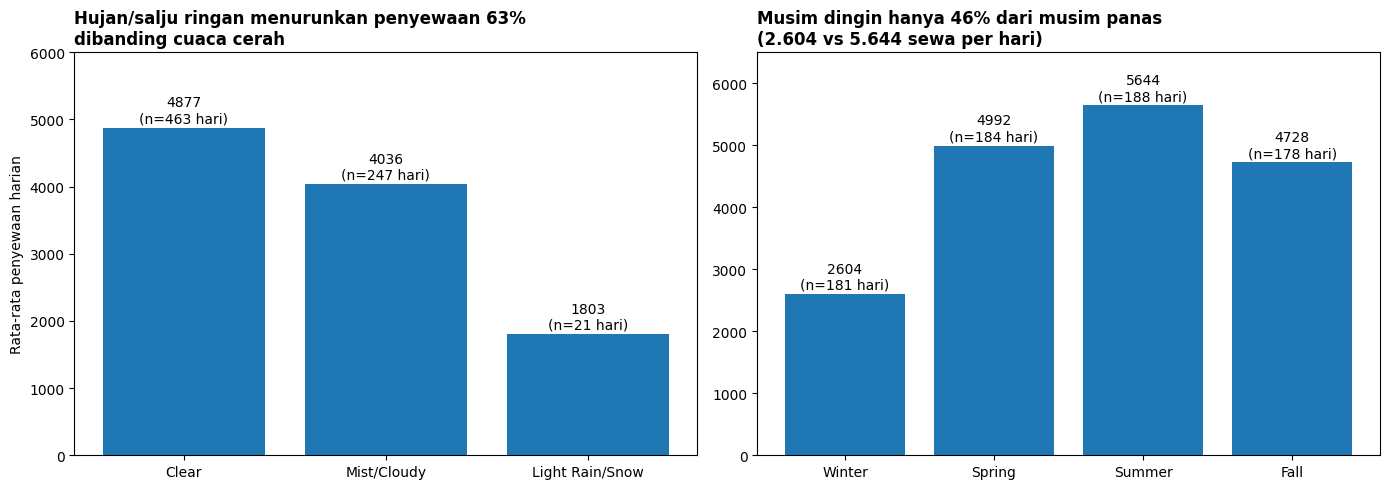

In [27]:
plt.figure(figsize=(14, 5))

# grafik kiri: cuaca (batang terendah disorot)
plt.subplot(1, 2, 1)
plt.bar(urut_cuaca, rata_cuaca.values)
for i in range(3):
    plt.text(i, rata_cuaca.values[i] + 80, str(round(rata_cuaca.values[i])) + "\n(n=" + str(hari_cuaca.values[i]) + " hari)", ha="center")
plt.title("Hujan/salju ringan menurunkan penyewaan 63%\ndibanding cuaca cerah", loc="left", fontweight="bold")
plt.ylabel("Rata-rata penyewaan harian")
plt.ylim(0, 6000)

# grafik kanan: musim (batang terendah disorot)
plt.subplot(1, 2, 2)
plt.bar(urut_musim, rata_musim.values)
for i in range(4):
    plt.text(i, rata_musim.values[i] + 80, str(round(rata_musim.values[i])) + "\n(n=" + str(hari_musim.values[i]) + " hari)", ha="center")
plt.title("Musim dingin hanya 46% dari musim panas\n(2.604 vs 5.644 sewa per hari)", loc="left", fontweight="bold")
plt.ylim(0, 6500)

plt.tight_layout()
plt.show()

### Pertanyaan 3: Berapa persen pertumbuhan total penyewaan tahun 2012 dibandingkan 2011, bulan apa yang tertinggi dan terendah, dan berapa porsi serta pertumbuhan pengguna registered dibanding casual, sebagai dasar perencanaan kapasitas armada dan strategi promosi keanggotaan?

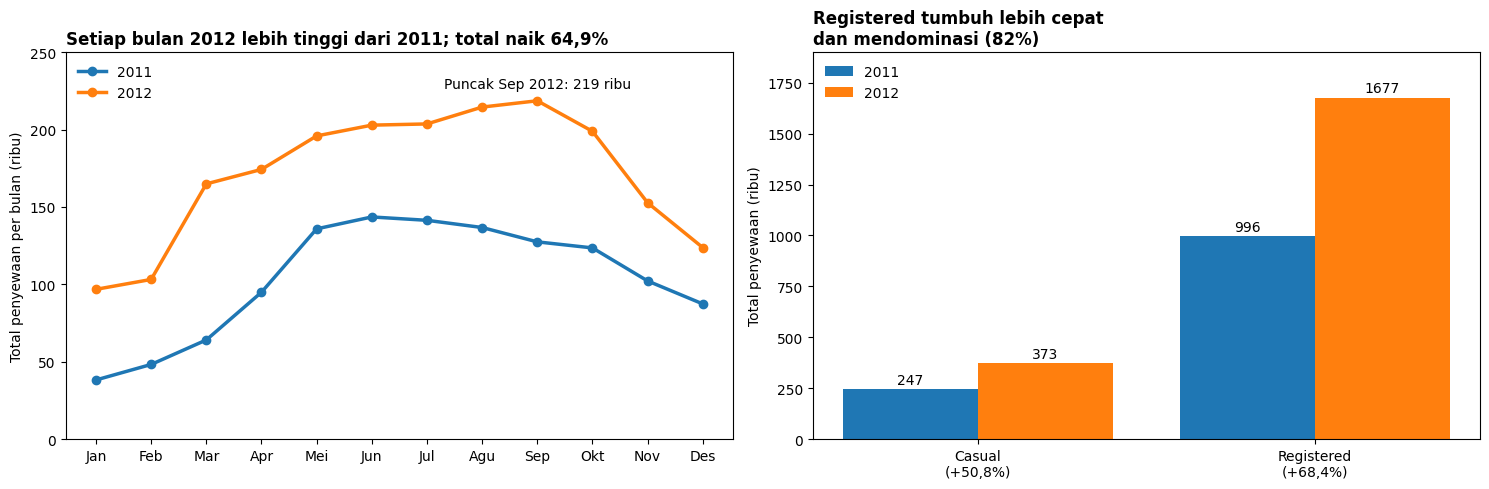

In [28]:
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

plt.figure(figsize=(15, 5))

# grafik kiri: total per bulan
plt.subplot(1, 2, 1)
plt.plot(nama_bulan, per_bulan[2011] / 1000, linewidth=2.5, marker="o", label="2011")
plt.plot(nama_bulan, per_bulan[2012] / 1000, linewidth=2.5, marker="o", label="2012")
plt.text(8, per_bulan[2012][9] / 1000 + 8, "Puncak Sep 2012: 219 ribu", ha="center")
plt.title("Setiap bulan 2012 lebih tinggi dari 2011; total naik 64,9%", loc="left", fontweight="bold")
plt.ylabel("Total penyewaan per bulan (ribu)")
plt.ylim(0, 250)
plt.legend(loc="upper left", frameon=False)

# grafik kanan: casual vs registered
plt.subplot(1, 2, 2)
x = [0, 1]
plt.bar([0 - 0.2, 1 - 0.2], [per_tahun.loc[2011, "casual"] / 1000, per_tahun.loc[2011, "registered"] / 1000], width=0.4, label="2011")
plt.bar([0 + 0.2, 1 + 0.2], [per_tahun.loc[2012, "casual"] / 1000, per_tahun.loc[2012, "registered"] / 1000], width=0.4, label="2012")
# tulis angka di atas batang
plt.text(-0.2, per_tahun.loc[2011, "casual"] / 1000 + 25, str(round(per_tahun.loc[2011, "casual"] / 1000)), ha="center")
plt.text(0.2, per_tahun.loc[2012, "casual"] / 1000 + 25, str(round(per_tahun.loc[2012, "casual"] / 1000)), ha="center")
plt.text(0.8, per_tahun.loc[2011, "registered"] / 1000 + 25, str(round(per_tahun.loc[2011, "registered"] / 1000)), ha="center")
plt.text(1.2, per_tahun.loc[2012, "registered"] / 1000 + 25, str(round(per_tahun.loc[2012, "registered"] / 1000)), ha="center")
plt.xticks(x, ["Casual\n(+50,8%)", "Registered\n(+68,4%)"])
plt.title("Registered tumbuh lebih cepat\ndan mendominasi (82%)", loc="left", fontweight="bold")
plt.ylabel("Total penyewaan (ribu)")
plt.ylim(0, 1900)
plt.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.show()

**Insight:**
- **Jam:** hari kerja memuncak pukul 17.00 (±525 sewa per jam), 18.00 (±492), dan 08.00 (±477); akhir pekan/libur memuncak pukul 13.00 (±373). Sebanyak 57,9% penyewaan hari kerja terjadi pada jam sibuk, Pada hari kerja, pukul 03.00–04.59 rata-rata hanya 5,2 sewa per jam, jam terendah hari kerja adalah pukul 03.00 (4,9) dan akhir pekan/libur pukul 04.00 (8,3).
- **Cuaca dan musim:** dibanding cuaca cerah (4.877 per hari), cuaca berkabut/mendung turun 17,2% (4.036) dan hujan/salju ringan turun 63,0% (1.803). Musim dingin (2.604) 53,9% lebih rendah daripada musim panas (5.644). Hari hujan/salju ringan hanya 21 hari, jadi angkanya berasal dari sampel kecil.
- **Pertumbuhan:** total penyewaan naik 64,9% (1.243.103 menjadi 2.049.576). *Registered* tumbuh 68,4% dan *casual* 50,8%, sehingga porsi *registered* naik dari 80,1% menjadi 81,8%. Puncak bulanan September 2012 (218.573) dan terendah Januari 2011 (38.189). Porsi *casual* 31,7% pada akhir pekan/libur dibanding 13,2% pada hari kerja.

## Analisis Lanjutan (Opsional)

Dataset ini tidak punya data pelanggan atau lokasi, jadi RFM dan geospatial analysis tidak cocok. Teknik yang dipakai adalah **Clustering tanpa machine learning (manual grouping dan binning)**:
- **Binning suhu** dengan `pd.cut`: Dingin (<10 °C), Sejuk (10–20 °C), Hangat (20–30 °C), Panas (>30 °C).
- **Kelas permintaan** dengan `pd.qcut`: hari dibagi tiga sama banyak menjadi Rendah, Sedang, dan Tinggi berdasarkan jumlah penyewaan.
- **Kelompok waktu** dengan `pd.cut`: Dini hari, Pagi, Siang, Sore, Malam.

**Tujuan:** melihat kondisi dan waktu mana yang paling menentukan permintaan, supaya jadwal distribusi sepeda, perawatan, dan promosi bisa lebih tepat.

#### Penyewaan berdasarkan kelompok suhu dan kelompok waktu

In [29]:
rata_suhu = day_df.groupby("temp_group")["cnt"].mean()
hari_suhu = day_df["temp_group"].value_counts().sort_index()
print(rata_suhu.round(0))

waktu = hour_df.groupby("time_of_day")["cnt"].sum()
persen_waktu = (waktu / waktu.sum() * 100).round(1)
print(persen_waktu)

temp_group
Dingin (<10 C)      1678.0
Sejuk (10-20 C)     3692.0
Hangat (20-30 C)    5662.0
Panas (>30 C)       5410.0
Name: cnt, dtype: float64
time_of_day
Dini hari (00-05)     3.2
Pagi (06-09)         19.1
Siang (10-15)        30.5
Sore (16-19)         33.4
Malam (20-23)        13.7
Name: cnt, dtype: float64


/tmp/ipykernel_12717/2578970876.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rata_suhu = day_df.groupby("temp_group")["cnt"].mean()
/tmp/ipykernel_12717/2578970876.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  waktu = hour_df.groupby("time_of_day")["cnt"].sum()


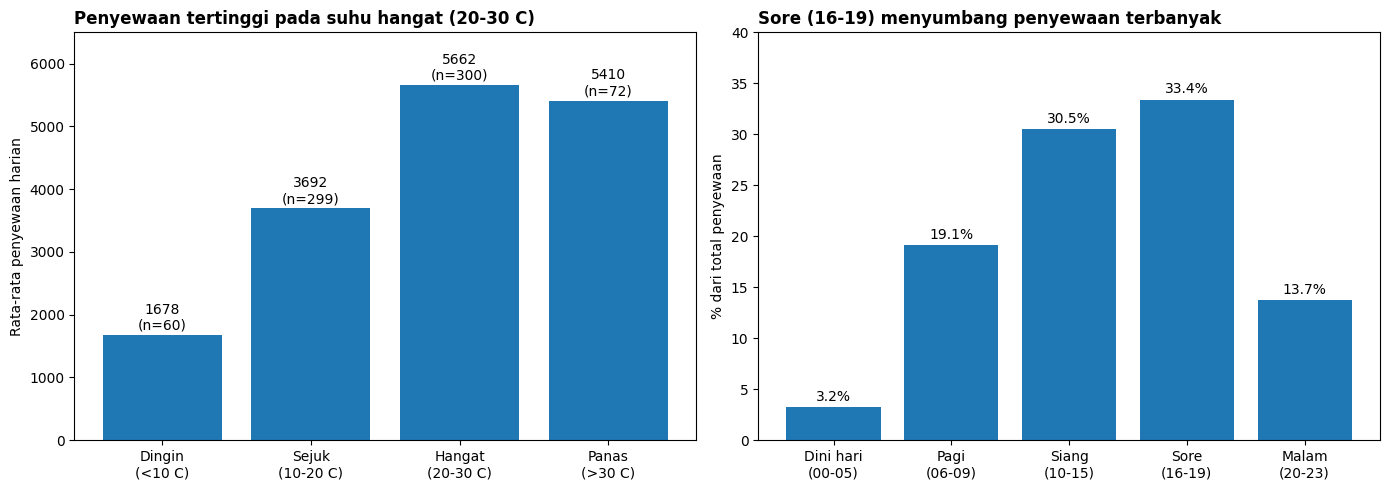

In [30]:
plt.figure(figsize=(14, 5))

# kiri: kelompok suhu (tertinggi disorot)
plt.subplot(1, 2, 1)
nama = ["Dingin\n(<10 C)", "Sejuk\n(10-20 C)", "Hangat\n(20-30 C)", "Panas\n(>30 C)"]
plt.bar(nama, rata_suhu.values)
for i in range(4):
    plt.text(i, rata_suhu.values[i] + 80, str(round(rata_suhu.values[i])) + "\n(n=" + str(hari_suhu.values[i]) + ")", ha="center")
plt.title("Penyewaan tertinggi pada suhu hangat (20-30 C)", loc="left", fontweight="bold")
plt.ylabel("Rata-rata penyewaan harian")
plt.ylim(0, 6500)

# kanan: kelompok waktu (sore disorot)
plt.subplot(1, 2, 2)
nama = ["Dini hari\n(00-05)", "Pagi\n(06-09)", "Siang\n(10-15)", "Sore\n(16-19)", "Malam\n(20-23)"]
plt.bar(nama, persen_waktu.values)
for i in range(5):
    plt.text(i, persen_waktu.values[i] + 0.6, str(persen_waktu.values[i]) + "%", ha="center")
plt.title("Sore (16-19) menyumbang penyewaan terbanyak", loc="left", fontweight="bold")
plt.ylabel("% dari total penyewaan")
plt.ylim(0, 40)

plt.tight_layout()
plt.show()

#### Kelas permintaan berdasarkan kondisi cuaca

Batas kelas permintaan: [3741. 5312.]
demand_tier      Rendah  Sedang  Tinggi
weather                                
Clear              26.1    34.6    39.3
Mist/Cloudy        42.1    33.2    24.7
Light Rain/Snow    90.5     9.5     0.0


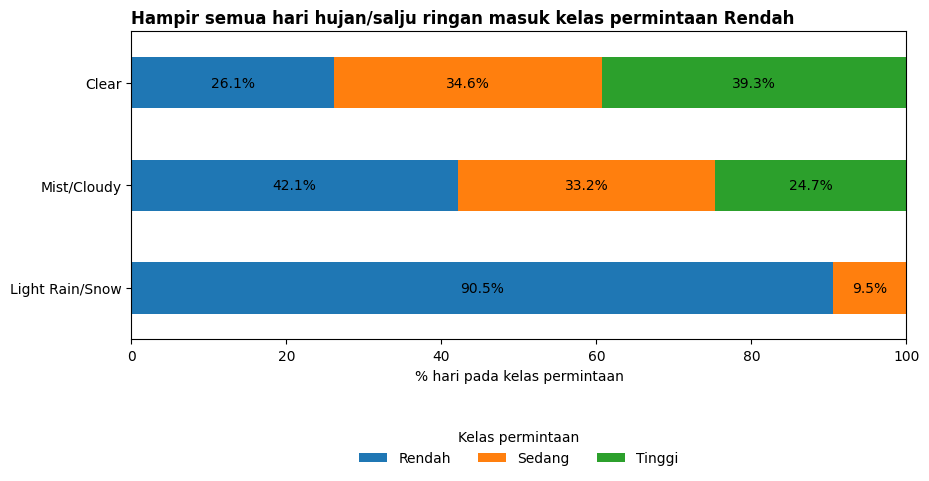

In [31]:
batas = day_df["cnt"].quantile([1 / 3, 2 / 3]).round(0)
print("Batas kelas permintaan:", batas.values)

kelas_cuaca = pd.crosstab(day_df["weather"], day_df["demand_tier"], normalize="index") * 100
kelas_cuaca = kelas_cuaca.loc[urut_cuaca].round(1)
print(kelas_cuaca)

kelas_cuaca.iloc[::-1].plot(kind="barh", stacked=True, figsize=(10, 4))
# tulis persentase pada tiap bagian batang
for i, cuaca in enumerate(kelas_cuaca.iloc[::-1].index):
    awal = 0
    for kelas in ["Rendah", "Sedang", "Tinggi"]:
        nilai = kelas_cuaca.loc[cuaca, kelas]
        if nilai > 5:
            plt.text(awal + nilai / 2, i, str(nilai) + "%", ha="center", va="center")
        awal = awal + nilai
plt.title("Hampir semua hari hujan/salju ringan masuk kelas permintaan Rendah", loc="left", fontweight="bold")
plt.xlabel("% hari pada kelas permintaan")
plt.ylabel("")
plt.xlim(0, 100)
plt.legend(title="Kelas permintaan", loc="lower center", bbox_to_anchor=(0.5, -0.45), ncol=3, frameon=False)
plt.show()

**Insight Analisis Lanjutan:**
- **Suhu:** penyewaan tertinggi pada suhu hangat 20–30 °C (5.662 per hari), sekitar 3,4 kali suhu dingin di bawah 10 °C (1.678). Suhu panas di atas 30 °C sedikit turun (5.410).
- **Waktu:** sore (16.00–19.59) menyumbang 33,4% total penyewaan, siang 30,5%, pagi 19,1%, malam 13,7%, dan dini hari hanya 3,2%.
- **Kelas permintaan:** 90,5% hari hujan/salju ringan masuk kelas Rendah dan tidak ada yang masuk kelas Tinggi, sedangkan pada cuaca cerah 39,3% hari masuk kelas Tinggi.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada hari kerja, rata-rata penyewaan tertinggi terjadi pukul 17.00 (525 sewa per jam), disusul pukul 18.00 (492) dan 08.00 (477); terendah pukul 03.00 (4,9). Pada akhir pekan/libur, tertinggi pukul 13.00 (373) dan terendah pukul 04.00 (8,3). Sebanyak 57,9% penyewaan hari kerja terjadi pada jam sibuk (07.00–09.59 dan 16.00–19.59).
- **Conclusion pertanyaan 2:** Rata-rata penyewaan per hari: Summer 5.644, Spring 4.992, Fall 4.728, Winter 2.604 (terendah, 53,9% di bawah Summer). Berdasarkan cuaca: Clear 4.877, Mist/Cloudy 4.036 (turun 17,2%), Light Rain/Snow 1.803 (terendah, turun 63,0%; hanya 21 hari sehingga sampelnya kecil). Sebanyak 90,5% hari Light Rain/Snow masuk kelas permintaan Rendah.
- **Conclusion pertanyaan 3:** Total penyewaan 2012 naik 64,9% dibanding 2011 (1.243.103 menjadi 2.049.576). Bulan tertinggi September 2012 (218.573) dan terendah Januari 2011 (38.189). Registered tumbuh 68,4% dan casual 50,8%; porsi registered naik dari 80,1% (2011) menjadi 81,8% (2012).
- **Analisis lanjutan:** sore hari (16.00–19.59) menyumbang 33,4% total penyewaan, dan penyewaan tertinggi pada suhu 20–30 °C (5.662 per hari).

**Rekomendasi Action Item:**
- **Penyediaan sepeda:** pada hari kerja, pastikan sepeda siap sebelum pukul 07.00 dan sebelum pukul 16.00 (jam sibuk memuat 57,9% penyewaan); pada akhir pekan/libur, siapkan armada untuk pukul 11.00–15.00 (puncak pukul 13.00).
- **Jadwal perawatan:** lakukan perawatan rutin pukul 04.00–04.59, jam dengan rata-rata terendah di kedua jenis hari (5,4 pada hari kerja dan 8,3 pada akhir pekan/libur).
- **Promosi dan perawatan besar:** jadwalkan perawatan armada besar pada Winter (2.604 sewa per hari, terendah) dan siapkan promo pada musim dan hari berkabut/mendung; kurangi sepeda yang disebar saat prakiraan hujan/salju ringan (1.803 sewa per hari).
- **Kapasitas armada:** total 2012 naik 64,9% dibanding 2011; siapkan kapasitas untuk Mei–Oktober (195.865–218.573 sewa per bulan pada 2012) dan pantau apakah pertumbuhan berlanjut pada tahun berikutnya.
- **Promosi keanggotaan:** casual mencapai 31,7% penyewaan pada akhir pekan/libur (13,2% pada hari kerja), jadi tawarkan promo keanggotaan pada akhir pekan/libur.